# ¿Dónde abrir centros de distribución? Localización de instalaciones con costo fijo

Problema clásico de localización: hay que decidir **qué centros abrir** (costo fijo) y **desde cuál atender a cada
cliente** (costo de transporte), cubriendo toda la demanda al menor costo total.

1. **Parte A – Ayudantía del ramo:** 5 clientes y 3 centros candidatos, resuelto en Gurobi y en PuLP (se reproduce
   el óptimo de 18.470).
2. **Parte B – Región de Coquimbo:** 15 comunas como demanda y 6 ciudades candidatas, con capacidad, distancias
   reales aproximadas y análisis de sensibilidad del costo fijo.

Es la decisión "estratégica" que va antes del ruteo diario (ver repo `vrptw-ruteo-farmacias`).

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pulp
from pathlib import Path

FIG = Path("../figures"); FIG.mkdir(exist_ok=True)
SOLVER = pulp.PULP_CBC_CMD(msg=False)

## Formulación (localización capacitada)

$$\min \sum_j f_j y_j + \sum_i \sum_j c_{ij} x_{ij}$$
s.a.
$\sum_j x_{ij} = d_i \;\forall i$ (se cubre la demanda) ·
$\sum_i x_{ij} \le Cap_j\, y_j \;\forall j$ (solo envía un centro abierto, hasta su capacidad) ·
$x_{ij} \le d_i\, y_j$ (desigualdad que ajusta la relajación) ·
$x_{ij} \ge 0,\; y_j \in \{0,1\}$

In [2]:
def solve_cflp(f, c, d, cap):
    """f: costo fijo por centro, c[i][j]: costo unitario cliente i desde centro j, d: demanda, cap: capacidad."""
    I, J = range(len(d)), range(len(f))
    m = pulp.LpProblem("CFLP", pulp.LpMinimize)
    x = pulp.LpVariable.dicts("x", [(i, j) for i in I for j in J], lowBound=0)
    y = pulp.LpVariable.dicts("y", J, cat="Binary")
    m += pulp.lpSum(f[j] * y[j] for j in J) + pulp.lpSum(c[i][j] * x[i, j] for i in I for j in J)
    for i in I:
        m += pulp.lpSum(x[i, j] for j in J) == d[i]
        for j in J:
            m += x[i, j] <= d[i] * y[j]
    for j in J:
        m += pulp.lpSum(x[i, j] for i in I) <= cap[j] * y[j]
    m.solve(SOLVER)
    X = pd.DataFrame([[x[i, j].value() for j in J] for i in I])
    return {"status": pulp.LpStatus[m.status], "obj": pulp.value(m.objective),
            "open": [j for j in J if y[j].value() > 0.5], "x": X,
            "fixed": sum(f[j] * y[j].value() for j in J)}

## Parte A – Ayudantía 6

In [3]:
f = [500, 500, 500]
c_centros = [[15, 35, 22, 23, 10],   # costo desde el centro 1 a cada cliente
             [47, 29, 18, 62, 11],
             [40, 25, 55, 17, 12]]
d = [80, 270, 250, 160, 180]
c = [[c_centros[j][i] for j in range(3)] for i in range(5)]   # c[cliente][centro]
solA = solve_cflp(f, c, d, cap=[1000] * 3)   # M = 1000 en la pauta
print(f"{solA['status']} | Costo total: {solA['obj']:,.0f} (pauta: 18.470) | Centros abiertos: {[j + 1 for j in solA['open']]}")
solA["x"].set_axis([f"Centro {j}" for j in (1, 2, 3)], axis=1).set_axis([f"Cliente {i}" for i in range(1, 6)]).round(0)

Optimal | Costo total: 18,470 (pauta: 18.470) | Centros abiertos: [1, 2, 3]


,Centro 1,Centro 2,Centro 3
Cliente 1,80.0,0.0,0.0
Cliente 2,0.0,0.0,270.0
Cliente 3,0.0,250.0,0.0
Cliente 4,0.0,0.0,160.0
Cliente 5,180.0,0.0,0.0


## Parte B – Red de distribución en la Región de Coquimbo

**Supuestos (todos editables):**
- Demanda mensual de cada comuna = 2 cajas por cada 100 habitantes (población aproximada del Censo 2017).
- Distancia por carretera ≈ 1,35 × distancia en línea recta entre capitales comunales.
- Costo de transporte: $25 por caja-km. Costos fijos mensuales y capacidades según el tamaño de la ciudad.

In [4]:
comunas = pd.DataFrame([
    ("La Serena",    -29.9045, -71.2489, 221054), ("Coquimbo",     -29.9533, -71.3436, 227730),
    ("Andacollo",    -30.2316, -71.0838,  11044), ("La Higuera",   -29.5097, -71.2611,   4241),
    ("Paihuano",     -30.0283, -70.5181,   4497), ("Vicuña",       -30.0319, -70.7081,  27771),
    ("Ovalle",       -30.6015, -71.1990, 111272), ("Monte Patria", -30.6930, -70.9580,  30751),
    ("Combarbalá",   -31.1780, -71.0030,  13322), ("Punitaqui",    -30.8290, -71.2580,  10956),
    ("Río Hurtado",  -30.4110, -70.9300,   4278), ("Illapel",      -31.6310, -71.1650,  30848),
    ("Salamanca",    -31.7750, -70.9640,  29347), ("Los Vilos",    -31.9110, -71.5100,  21382),
    ("Canela",       -31.3960, -71.4560,   9093),
], columns=["comuna", "lat", "lon", "poblacion"])
comunas["demanda"] = (comunas.poblacion * 0.02).round()

candidatos = pd.DataFrame([
    ("La Serena", 9.0, 12000), ("Coquimbo", 8.0, 12000), ("Ovalle", 6.0, 6000),
    ("Vicuña", 4.0, 3000), ("Illapel", 4.5, 3000), ("Los Vilos", 4.5, 3000),
], columns=["comuna", "costo_fijo_MM", "capacidad"])
candidatos = candidatos.merge(comunas[["comuna", "lat", "lon"]], on="comuna")
print(f"Demanda total: {comunas.demanda.sum():,.0f} cajas/mes | Capacidad total: {candidatos.capacidad.sum():,} cajas/mes")
candidatos

Demanda total: 15,152 cajas/mes | Capacidad total: 39,000 cajas/mes


,comuna,costo_fijo_MM,capacidad,lat,lon
0,La Serena,9.0,12000,-29.9045,-71.2489
1,Coquimbo,8.0,12000,-29.9533,-71.3436
2,Ovalle,6.0,6000,-30.6015,-71.1990
3,Vicuña,4.0,3000,-30.0319,-70.7081
4,Illapel,4.5,3000,-31.6310,-71.1650
5,Los Vilos,4.5,3000,-31.9110,-71.5100


In [5]:
def haversine(a, b):
    R = 6371.0
    la1, lo1, la2, lo2 = map(math.radians, (a[0], a[1], b[0], b[1]))
    h = math.sin((la2 - la1) / 2) ** 2 + math.cos(la1) * math.cos(la2) * math.sin((lo2 - lo1) / 2) ** 2
    return 2 * R * math.asin(math.sqrt(h))

ROAD, CLP_CAJA_KM = 1.35, 25
km = [[ROAD * haversine((r.lat, r.lon), (s.lat, s.lon)) for s in candidatos.itertuples()] for r in comunas.itertuples()]
cost = [[k * CLP_CAJA_KM for k in row] for row in km]
fixed = list(candidatos.costo_fijo_MM * 1e6)

solB = solve_cflp(fixed, cost, list(comunas.demanda), list(candidatos.capacidad))
abiertos = candidatos.comuna[solB["open"]].tolist()
print(f"{solB['status']} | Costo mensual: ${solB['obj'] / 1e6:,.1f} MM "
      f"(fijo {solB['fixed'] / 1e6:,.1f} + transporte {(solB['obj'] - solB['fixed']) / 1e6:,.1f}) | Abre: {abiertos}")

Optimal | Costo mensual: $24.6 MM (fijo 18.5 + transporte 6.1) | Abre: ['Coquimbo', 'Ovalle', 'Illapel']


In [6]:
asig = solB["x"].copy()
asig.columns = pd.Index(candidatos.comuna, name="centro"); asig.index = pd.Index(comunas.comuna, name="comuna")
asignacion = asig.stack().loc[lambda s: s > 0.5].rename("cajas").reset_index()
asignacion["km"] = [km[comunas.index[comunas.comuna == a].item()][candidatos.index[candidatos.comuna == b].item()]
                    for a, b in zip(asignacion.comuna, asignacion.centro)]
asignacion.round(1).to_csv("../data/asignacion_region_coquimbo.csv", index=False)
uso = asig.sum().loc[abiertos] / candidatos.set_index("comuna").capacidad.loc[abiertos]
print("Uso de capacidad:", uso.map("{:.0%}".format).to_dict())
asignacion.round(1)

Uso de capacidad: {'Coquimbo': '83%', 'Ovalle': '52%', 'Illapel': '69%'}


,comuna,centro,cajas,km
0,La Serena,Coquimbo,4421.0,14.3
1,Coquimbo,Coquimbo,4555.0,0.0
2,Andacollo,Coquimbo,221.0,53.7
3,La Higuera,Coquimbo,85.0,67.5
4,Paihuano,Coquimbo,90.0,107.9
5,Vicuña,Coquimbo,555.0,83.5
6,Ovalle,Ovalle,2225.0,0.0
7,Monte Patria,Ovalle,615.0,34.0
8,Combarbalá,Illapel,266.0,71.1
9,Punitaqui,Ovalle,219.0,35.0


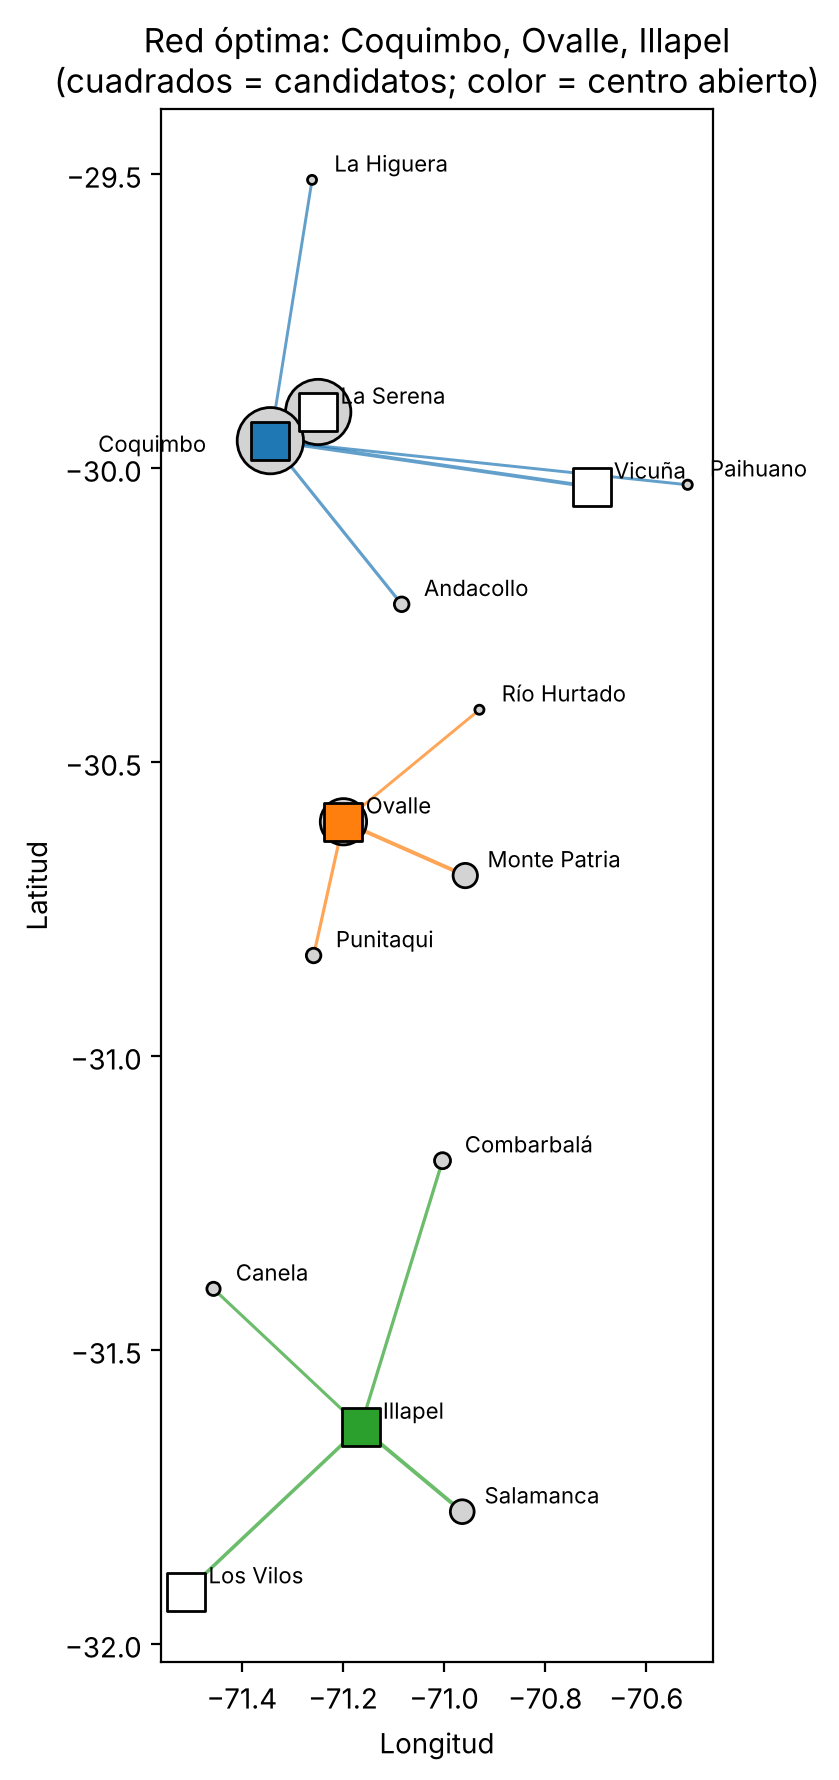

In [7]:
fig, ax = plt.subplots(figsize=(7, 9))
colors = dict(zip(abiertos, plt.cm.tab10.colors))
for r in asignacion.itertuples():
    a = comunas.set_index("comuna").loc[r.comuna]; b = candidatos.set_index("comuna").loc[r.centro]
    ax.plot([a.lon, b.lon], [a.lat, b.lat], color=colors[r.centro], lw=1 + r.cajas / 1500, alpha=0.7)
ax.scatter(comunas.lon, comunas.lat, s=comunas.demanda / 8, color="lightgray", edgecolor="k", zorder=3)
for r in candidatos.itertuples():
    ax.scatter(r.lon, r.lat, marker="s", s=180, zorder=4,
               color=colors.get(r.comuna, "white"), edgecolor="k")
for r in comunas.itertuples():
    off = (-62, -4) if r.comuna == "Coquimbo" else (8, 3)
    ax.annotate(r.comuna, (r.lon, r.lat), xytext=off, textcoords="offset points", fontsize=8)
ax.set_title(f"Red óptima: {', '.join(abiertos)}\n(cuadrados = candidatos; color = centro abierto)")
ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud"); ax.set_aspect(1 / math.cos(math.radians(30.7)))
plt.tight_layout(); plt.savefig(FIG / "red_region_coquimbo.png", dpi=120); plt.show()

## Sensibilidad: ¿qué pasa si el costo fijo sube o baja?

In [8]:
rows = []
for factor in [0.1, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 5.0]:
    s = solve_cflp([v * factor for v in fixed], cost, list(comunas.demanda), list(candidatos.capacidad))
    rows.append({"Factor costo fijo": factor, "Centros abiertos": len(s["open"]),
                 "Abre": ", ".join(candidatos.comuna[s["open"]]),
                 "Costo total (MM)": s["obj"] / 1e6, "Transporte (MM)": (s["obj"] - s["fixed"]) / 1e6})
sens = pd.DataFrame(rows)
sens.round(2)

,Factor costo fijo,Centros abiertos,Abre,Costo total (MM),Transporte (MM)
0,0.10,6,"La Serena, Coquimbo, Ovalle, Vicuña, Illapel, ...",6.09,2.49
1,0.25,4,"Coquimbo, Ovalle, Vicuña, Illapel",10.37,4.74
2,0.50,3,"Coquimbo, Ovalle, Illapel",15.34,6.09
3,0.75,3,"Coquimbo, Ovalle, Illapel",19.96,6.09
4,1.00,3,"Coquimbo, Ovalle, Illapel",24.59,6.09
5,1.50,2,"Coquimbo, Ovalle",33.55,12.55
6,2.00,2,"Coquimbo, Ovalle",40.55,12.55
7,3.00,2,"Coquimbo, Ovalle",54.55,12.55
8,5.00,2,"Coquimbo, Ovalle",82.55,12.55


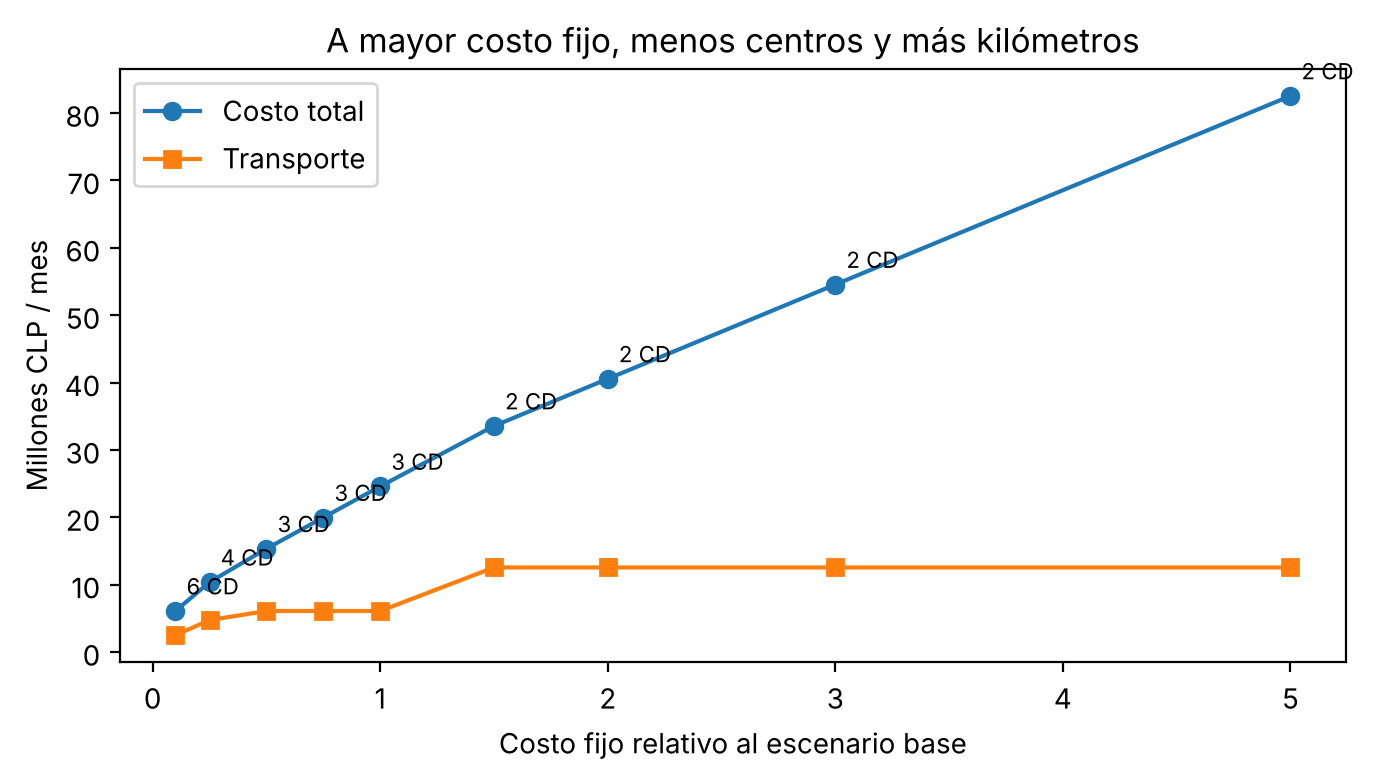

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sens["Factor costo fijo"], sens["Costo total (MM)"], "-o", label="Costo total")
ax.plot(sens["Factor costo fijo"], sens["Transporte (MM)"], "-s", label="Transporte")
for fx, n_cd, tot in zip(sens["Factor costo fijo"], sens["Centros abiertos"], sens["Costo total (MM)"]):
    ax.annotate(f"{n_cd} CD", (fx, tot), xytext=(4, 6), textcoords="offset points", fontsize=8)
ax.set_xlabel("Costo fijo relativo al escenario base"); ax.set_ylabel("Millones CLP / mes"); ax.legend()
ax.set_title("A mayor costo fijo, menos centros y más kilómetros")
plt.tight_layout(); plt.savefig(FIG / "sensibilidad.png", dpi=120); plt.show()

## Conclusiones
- El modelo en PuLP reproduce el óptimo de la ayudantía (18.470) abriendo los mismos centros.
- En la región, la conurbación La Serena–Coquimbo concentra ~59 % de la demanda, por lo que siempre conviene un
  centro ahí (Coquimbo, por costo fijo menor y cercanía). En el escenario base la red óptima es
  **Coquimbo + Ovalle + Illapel** (≈ $24,6 MM/mes): un centro por provincia.
- Si el costo fijo sube 50 % o más, conviene cerrar Illapel y atender el Choapa desde Ovalle (el transporte se
  duplica, pero se ahorra el arriendo); si baja a la cuarta parte, se agrega Vicuña para el valle de Elqui.
- La sensibilidad muestra el *trade-off* típico: si arrendar bodega es barato conviene descentralizar; si es caro,
  se concentra y se paga más transporte.
- Siguiente paso: usar ventas reales por comuna y la matriz de distancias de la red vial, y luego planificar las
  rutas desde cada centro con el modelo VRPTW.